# Copia de consulta — no editar ni usar para entrenar

Original: `notebooks/06_clasificacion_resnet50.ipynb` · SHA-256 (UTF-8, saltos LF): `d471dc4488a8019899f17e41850e2b9060e4a37bccb9343168043bdef6ab9610`.

Tipo: **consulta_guardada**. Fecha de ejecución/consulta: 2026-11-10T03:26:05.672265+00:00. Commit de ejecución: `92f76cf1e05f11a43be6d79a29c6e515d17f2721`.

Entorno de ejecución: `{"Pillow": "12.1.1", "figure_dpi": 55, "matplotlib": "3.10.8", "nbclient": "0.10.4", "numpy": "1.26.4", "pandas": "2.2.2", "python": "3.11.9", "scikit-learn": "1.7.2", "sistema": "Windows-10-10.0.26200-SP0"}`. Publicación: 2026-11-10T00:35:59-03:00. Commit de referencia del código: `92f76cf1e05f11a43be6d79a29c6e515d17f2721`.

Preparación del insumo: sin celdas omitidas.

Celdas ejecutadas (índices del original): [19]. Familia del test: no aplica.

Una consulta de corridas guardadas muestra resultados reales ya existentes; no reproduce los logs del entrenamiento. Val eligió checkpoints y se usa para reportar. Se quitaron widgets y formatos activos; en test se quitaron todas las imágenes.


<a href="https://colab.research.google.com/github/candeperles/PDI-TP/blob/main/notebooks/06_clasificacion_resnet50.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 06. Clasificación con ResNet50

Clasificación de paneles solares: ImageNet congelado, fine-tuning de todo el extractor y pesos aleatorios.

**Empezá en una sesión de Colab con GPU T4 y ejecutá de arriba hacia abajo.**

1. Autorizá el acceso a Drive cuando Colab lo pida (`drive.mount`, igual que el resto de los notebooks).

Cada variante se guarda con el formato común del equipo en `Mi unidad/PDI-TP/resultados/<modelo>/<modo>/`:
`resnet50/imagenet_congelado`, `resnet50/imagenet_finetuning`, `resnet50/aleatorio` y `baseline/siempre_con_paneles`.
Dentro de cada una: pesos (`mejor.keras`, y `ultimo.keras` para reanudar), `metricas.json`,
`predicciones_val.csv` (predicción contra el real), `config.json`, historial, curvas y matriz de confusión.

Los checkpoints se escriben directo en Drive, así que si se corta la sesión se puede volver a ejecutar todo:
las variantes completas se saltean y una etapa a medias continúa desde `ultimo.keras`. `REPETIR = True`
vuelve a entrenar (la corrida anterior se archiva como `<modo>__anterior_<fecha>`, no se borra).

El split y los datos originales se conservan. Las referencias N06/N16 siguen siendo provisionales; se informa
además la evaluación sin esos casos. Val selecciona checkpoints: no es un test independiente.

**Receta común del issue #15:** volver a correr los tres modos con `REPETIR = True`.
Las corridas anteriores no corresponden a esta receta; no hay resultados nuevos hasta entrenar.


In [ ]:
# 1. Opciones: solo hace falta cambiar estos valores.
REPETIR = False  # True vuelve a entrenar variantes que ya están completas (archiva las anteriores)

SEMILLA = 42
LADO = 256
BATCH = 32
EPOCAS_CABEZA = 30
EPOCAS_FINE = 20
EPOCAS_ALEATORIO = 60
UMBRAL = 0.5
DROPOUT = 0.3
PACIENCIA = 10
PACIENCIA_ALEATORIO = 10
MOMENTUM_BN_ALEATORIO = 0.9  # batch normalization desde cero
INICIO_PARADA_ALEATORIO = 20  # el early stopping cuenta (y elige el mejor) desde esta época


In [ ]:
# 2. Preparar dependencias, código compartido y Drive.
import importlib.util
import subprocess
import sys
import os
from pathlib import Path

if importlib.util.find_spec("google.colab") is None:
    raise RuntimeError("Este notebook está preparado para Google Colab. Abrilo allí con GPU T4.")
for paquete, modulo in [
    ("tensorflow>=2.20,<2.22", "tensorflow"), ("numpy", "numpy"),
    ("pandas", "pandas"), ("Pillow", "PIL"), ("matplotlib", "matplotlib"),
    ("scikit-learn", "sklearn")]:
    if importlib.util.find_spec(modulo) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", paquete], check=True)

repo = Path("/content/PDI-TP")
if repo.is_dir():
    subprocess.run(["git", "-C", str(repo), "pull", "--ff-only", "-q"], check=True)
else:
    subprocess.run(["git", "clone", "-q", "https://github.com/candeperles/PDI-TP.git", str(repo)], check=True)
os.chdir(repo)
sys.path.insert(0, str(repo))

import json
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from importlib.metadata import version
from pdi_tp import aumentacion, entorno, resultados, clasificacion as clf

rutas = entorno.preparar()  # monta Drive
gpus = tf.config.list_physical_devices("GPU")
if not gpus:
    raise RuntimeError("Activá GPU T4 en Entorno de ejecución > Cambiar tipo de entorno y volvé a empezar.")
for gpu in gpus:
    tf.config.experimental.set_memory_growth(gpu, True)
keras.utils.set_random_seed(SEMILLA)
tf.config.experimental.enable_op_determinism()
print("Python:", platform.python_version(), "TensorFlow:", tf.__version__, "GPU:", gpus)

MODELO = "resnet50"  # carpetas en Drive: resultados/resnet50/<modo>/
ANALISIS = rutas.analisis / "resnet50"  # manifiesto y cajas derivadas (no son resultados de un modelo)
ANALISIS.mkdir(parents=True, exist_ok=True)


## Referencia y preparación reproducible

Se auditan los 900 pares. Solo se permite excluir Z01/línea 1, de ancho cero, según criterios v1.
Se guardan un manifiesto binario y metadatos por caja, con clase y confianza originales.
No se necesita copiar imágenes para clasificación. Las cajas positivas pequeñas y las clases 1/2 se conservan.

**N06 y N16 siguen pendientes**: `y` permanece vacío y `y_original=0` conserva lo entregado.
Se guardan predicciones para las 162 imágenes. Las métricas completas y la selección de checkpoints
usan provisionalmente la referencia original; se añade análisis de sensibilidad sobre los 160 casos
sin duda registrada. Esto no confirma semánticamente las otras etiquetas ni reemplaza la segunda revisión.

In [ ]:
tabla, cajas = clf.preparar_tabla(rutas)
tabla.to_csv(ANALISIS / "manifiesto.csv", index=False)
cajas.to_csv(ANALISIS / "cajas_derivadas.csv", index=False)
train = tabla.query("split == 'train'").reset_index(drop=True)
val = tabla.query("split == 'val'").reset_index(drop=True)
PESOS_MUESTRA = clf.pesos_muestra_fuente_clase(train.fuente.to_numpy(), train.y.to_numpy(dtype=int))
PESOS_VAL = np.ones(len(val), dtype="float32")
HUELLA = clf.huella_tabla(tabla)
display(tabla.groupby(["split", "y_original", "pendiente_revision"]).size().rename("imagenes").to_frame())
display(val.loc[val.pendiente_revision, ["archivo", "y", "y_original"]])
print("Pesos fuente x clase: media", PESOS_MUESTRA.mean(), "\nHuella:", HUELLA)
config = dict(modelo="ResNet50", receta="comun_v2", img_size=LADO, batch_size=BATCH, semilla=SEMILLA,
    augmentation="aumentacion.google_maps", aumentos="rotacion + flip + color + desenfoque + compresion JPEG",
    dropout=DROPOUT, cabeza="GlobalAveragePooling2D, Dropout, Dense sigmoid",
    umbral=UMBRAL, clase_positiva=1, promedio="binary",
    pesos_muestra="igual_masa_por_fuente_x_clase",
    criterio_datos="v1; excluir solo Z01 linea 1; conservar cajas pequenas y confianza",
    huella_manifiesto=HUELLA, n_train=len(train), n_val=len(val),
    evaluacion="provisional; referencia original; N06/N16 pendientes",
    monitor="val_loss", restaurar_mejores_pesos=True, optimizador="Adam", loss="binary_crossentropy",
    preprocesamiento="ResNet preprocess_input sobre RGB 0..255, incluido en modelo",
    entorno=dict(python=platform.python_version(),
                 paquetes={p: version(p) for p in ["tensorflow", "keras", "numpy", "pandas", "Pillow", "scikit-learn"]},
                 gpu=[str(g) for g in gpus]))


## Modelo y checkpoints

Keras escribe los checkpoints directo en la carpeta de Drive de cada variante. Volver a ejecutar una etapa
finalizada carga su mejor checkpoint; una etapa incompleta continúa desde `ultimo.keras`, conservando Adam,
las épocas del historial y el mejor checkpoint, aunque sea en otra sesión de Colab.


In [ ]:
"""Entrenamiento ResNet50 con TensorFlow/Keras; importar en el entorno de modelos."""
import numpy as np
import tensorflow as tf
from tensorflow import keras


def dataset(tabla, lado=256, batch=32, entrenamiento=False, semilla=42, pesos_muestra=None):
    """RGB 0..255 -> preprocess_input de ResNet; val conserva el orden del manifiesto."""
    pesos = np.ones(len(tabla), dtype="float32") if pesos_muestra is None else np.asarray(pesos_muestra, dtype="float32")
    if len(pesos) != len(tabla):
        raise ValueError("pesos_muestra debe estar alineado con tabla")
    ds = tf.data.Dataset.from_tensor_slices((tabla.ruta.to_list(), tabla.y_original.to_numpy(dtype="float32"), pesos))
    if entrenamiento:
        ds = ds.shuffle(len(tabla), seed=semilla, reshuffle_each_iteration=True)

    def leer(ruta, etiqueta, peso):
        imagen = tf.io.decode_png(tf.io.read_file(ruta), channels=3)
        imagen = tf.image.resize(imagen, (lado, lado))
        return imagen, tf.reshape(etiqueta, (1,)), peso

    ds = ds.map(leer, num_parallel_calls=tf.data.AUTOTUNE)
    if entrenamiento:
        ds = ds.map(lambda imagen, etiqueta, peso: (aumentacion.google_maps(imagen), etiqueta, peso),
                    num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(batch).prefetch(tf.data.AUTOTUNE)


def construir(lado=256, preentrenado=True, dropout=0.3, semilla=42, momentum_batchnorm=None):
    base = keras.applications.ResNet50(include_top=False,
        weights="imagenet" if preentrenado else None, input_shape=(lado, lado, 3))
    if momentum_batchnorm is not None:
        for capa in base.layers:
            if isinstance(capa, keras.layers.BatchNormalization):
                capa.momentum = momentum_batchnorm
    base.trainable = not preentrenado
    entrada = keras.Input((lado, lado, 3), name="rgb_0_255")
    x = entrada
    # La aumentación común se aplica en el dataset de entrenamiento.
    # ResNet espera BGR centrado en medias ImageNet. No dividir por 255.
    x = keras.applications.resnet.preprocess_input(x)
    # ImageNet: BatchNorm en inferencia incluso durante fine-tuning.
    # Desde cero: BatchNorm debe aprender sus estadísticas.
    x = base(x, training=False) if preentrenado else base(x)
    x = keras.layers.GlobalAveragePooling2D()(x)
    x = keras.layers.Dropout(dropout, seed=semilla + 2)(x)
    salida = keras.layers.Dense(1, activation="sigmoid", name="con_paneles")(x)
    return keras.Model(entrada, salida, name="clasificador_resnet50"), base


def descongelar(base):
    """Ajusta todo el extractor; mantiene BatchNormalization congelada."""
    base.trainable = True
    for capa in base.layers:
        capa.trainable = not isinstance(capa, keras.layers.BatchNormalization)


def compilar(modelo, lr):
    modelo.compile(optimizer=keras.optimizers.Adam(learning_rate=lr),
                   loss="binary_crossentropy", metrics=[keras.metrics.BinaryAccuracy(name="accuracy")])


class ReduccionReanudada(keras.callbacks.ReduceLROnPlateau):
    """Recupera la espera del scheduler; el LR vigente queda guardado en ultimo.keras."""
    def __init__(self, valores):
        super().__init__(monitor="val_loss", mode="min", factor=0.5, patience=3)
        self.valores_previos = list(valores)

    def on_train_begin(self, logs=None):
        super().on_train_begin(logs)
        self.best = float("inf")
        for valor in self.valores_previos:
            if valor < self.best - self.min_delta:
                self.best = valor
                self.wait = 0
            else:
                self.wait += 1
                if self.wait >= self.patience:
                    self.wait = 0


class ParadaReanudada(keras.callbacks.EarlyStopping):
    def __init__(self, valores, paciencia=5, inicio=0):
        super().__init__(monitor="val_loss", mode="min", patience=paciencia, restore_best_weights=True,
                         start_from_epoch=inicio)
        self.valores_previos = list(valores)[inicio:]

    def on_train_begin(self, logs=None):
        super().on_train_begin(logs)
        if self.valores_previos:
            self.best = min(self.valores_previos)
            self.wait = len(self.valores_previos) - 1 - int(np.argmin(self.valores_previos))


class MejorDesde(keras.callbacks.Callback):
    """Guarda el mejor modelo según val_loss, sin contar las épocas anteriores a `inicio`."""
    def __init__(self, ruta, valores, inicio=0):
        super().__init__()
        self.ruta, self.inicio = ruta, inicio
        previos = list(valores)[inicio:]
        self.best = min(previos) if previos else float("inf")

    def on_epoch_end(self, epoch, logs=None):
        valor = (logs or {}).get("val_loss")
        if epoch >= self.inicio and valor is not None and valor < self.best:
            self.best = valor
            self.model.save(self.ruta)


def entrenar(modelo, train_ds, val_ds, carpeta, epocas, lr, paciencia=5, reducir_lr=False, inicio_parada=0):
    carpeta.mkdir(parents=True, exist_ok=True)
    terminado = carpeta / "completado.json"
    if terminado.exists():
        modelo.load_weights(carpeta / "mejor.keras")
        print("Etapa ya terminada; se cargó el mejor checkpoint:", carpeta.name)
        return modelo
    historial = carpeta / "historia.csv"
    ultimo = carpeta / "ultimo.keras"
    mejor = carpeta / "mejor.keras"
    previo = pd.read_csv(historial) if historial.exists() else pd.DataFrame()
    inicial = len(previo)
    valores = []
    if inicial:
        if not ultimo.exists() or (not mejor.exists() and inicial > inicio_parada):
            raise RuntimeError("Hay historial pero falta un checkpoint. No se sobrescribió nada; conservá la sesión para recuperar los archivos.")
        if not np.array_equal(previo.epoch.to_numpy(), np.arange(inicial)) or not np.isfinite(previo.val_loss).all():
            raise RuntimeError("El historial está incompleto o no es finito. No se modificaron los checkpoints.")
        # El modelo completo conserva pesos y estado de Adam; no recompilarlo.
        modelo = keras.models.load_model(ultimo)
        if int(modelo.optimizer.iterations.numpy()) != inicial * len(train_ds):
            raise RuntimeError("El último checkpoint y el historial no coinciden. No se sobrescribió nada.")
        valores = previo.val_loss.to_list()
        print(f"Reanudando {carpeta.name} desde la época {inicial + 1}; se conservan las {inicial} anteriores.")
    else:
        if ultimo.exists() or mejor.exists():
            raise RuntimeError("Hay checkpoints sin historial de épocas; no se sobrescribieron.")
        compilar(modelo, lr)
    contados = valores[inicio_parada:]
    espera = len(contados) - 1 - int(np.argmin(contados)) if contados else 0
    if inicial < epocas and espera < paciencia:
        historia = modelo.fit(train_ds, validation_data=val_ds, epochs=epocas,
            initial_epoch=inicial, callbacks=[
                keras.callbacks.TerminateOnNaN(),
                MejorDesde(str(mejor), valores, inicio_parada),
                keras.callbacks.CSVLogger(str(historial), append=bool(inicial)),
                ParadaReanudada(valores, paciencia, inicio_parada),
            ] + ([ReduccionReanudada(valores)] if reducir_lr else [])
              + [keras.callbacks.ModelCheckpoint(str(ultimo))], verbose=2)
        if not all(np.isfinite(v).all() for v in historia.history.values()):
            raise RuntimeError("Entrenamiento no finito. No se registra como completado.")
    modelo.load_weights(mejor)
    terminado.write_text(json.dumps({"epocas": len(pd.read_csv(historial)), "monitor": "val_loss"}))
    return modelo


from types import SimpleNamespace
rn = SimpleNamespace(dataset=dataset, construir=construir, descongelar=descongelar, entrenar=entrenar)


## Evaluación común y baseline

La matriz usa filas = referencia, columnas = predicción, orden `[sin paneles, con paneles]`.
Se exporta una fila por imagen con nombre, fuente, grupo, referencia, probabilidad y predicción
para la futura comparación con los detectores. Se informa también el baseline «siempre con paneles».
Los archivos `.keras` incluyen preprocesamiento y esperan imágenes RGB en 0..255.

In [ ]:
def evaluar_guardar(carpeta, probabilidades, params, modelo=None):
    """Guarda la variante con el formato común (resultados.guardar_corrida) y agrega sus extras."""
    p = np.asarray(probabilidades).reshape(-1)
    mascara = ~val.pendiente_revision.to_numpy()
    extra = {"sin_pendientes": clf.evaluar(val.loc[mascara, "y_original"].to_numpy(dtype=int), p[mascara], UMBRAL)}
    if modelo is not None:
        extra["parametros_modelo"] = dict(total=modelo.count_params(),
            entrenables=int(sum(np.prod(w.shape) for w in modelo.trainable_weights)))
    metricas = resultados.guardar_corrida(rutas, carpeta, archivos=val.archivo, probabilidad=p,
        params=dict(config, **params), umbral=UMBRAL, metricas_extra=extra, sin_pesos=modelo is None)
    from sklearn.metrics import ConfusionMatrixDisplay
    fig, ax = plt.subplots(figsize=(5, 4))
    ConfusionMatrixDisplay(np.array(metricas["matriz_confusion"]),
        display_labels=["sin paneles", "con paneles"]).plot(ax=ax, colorbar=False)
    ax.set_title(f"{carpeta.parent.name}/{carpeta.name} · referencia provisional")
    fig.tight_layout()
    fig.savefig(carpeta / "matriz_confusion.png", dpi=130)
    plt.show()
    plt.close(fig)
    return pd.read_csv(carpeta / "predicciones_val.csv")

def curvas(carpeta):
    historia = pd.read_csv(carpeta / "historia.csv")
    fig, axs = plt.subplots(1, 2, figsize=(10, 3))
    for ax, metrica in zip(axs, ["loss", "accuracy"]):
        ax.plot(historia.epoch + 1, historia[metrica], label="train")
        ax.plot(historia.epoch + 1, historia["val_" + metrica], label="val")
        ax.set(xlabel="Época", ylabel=metrica, title=carpeta.name)
        ax.legend()
    fig.tight_layout()
    fig.savefig(carpeta / "curvas.png", dpi=130)
    plt.show()
    plt.close(fig)

def preparar_variante(modelo, modo):
    """Carpeta de la variante y si ya está completa (en ese caso se reutiliza, salvo REPETIR)."""
    carpeta = resultados.ruta_corrida(rutas, modelo, modo)
    if resultados.corrida_completa(carpeta) and not REPETIR:
        print(f"Ya completa, se reutiliza: {modelo}/{modo}")
        return carpeta, True
    return resultados.carpeta_corrida(rutas, modelo, modo, reiniciar=REPETIR), False

carpeta, hecha = preparar_variante("baseline", "siempre_con_paneles")
if not hecha:
    evaluar_guardar(carpeta, np.ones(len(val)), dict(estrategia="baseline"))


## 1. ImageNet: entrenar solo la cabeza

El extractor queda congelado. `preprocess_input` convierte RGB a BGR y resta las medias de ImageNet;
no dividir los píxeles por 255. Los aumentos solo se activan al entrenar.

In [ ]:
keras.backend.clear_session()
keras.utils.set_random_seed(SEMILLA)
train_ds = rn.dataset(train, LADO, BATCH, entrenamiento=True, semilla=SEMILLA, pesos_muestra=PESOS_MUESTRA)
val_ds = rn.dataset(val, LADO, BATCH, pesos_muestra=PESOS_VAL)
modelo, base = rn.construir(LADO, preentrenado=True, dropout=DROPOUT, semilla=SEMILLA)
modelo.summary()
carpeta, hecha = preparar_variante(MODELO, "imagenet_congelado")
if hecha:
    modelo.load_weights(carpeta / "mejor.keras")  # la etapa 2 parte de este checkpoint
else:
    modelo = rn.entrenar(modelo, train_ds, val_ds, carpeta, EPOCAS_CABEZA, 1e-3, paciencia=PACIENCIA)
    evaluar_guardar(carpeta, modelo.predict(val_ds, verbose=0),
        dict(estrategia="extractor_congelado", inicializacion="imagenet", lr=1e-3, epocas_max=EPOCAS_CABEZA, paciencia=PACIENCIA, reducir_lr=None), modelo)
    curvas(carpeta)
CARPETA_CABEZA = carpeta


## 2. ImageNet: ajuste fino de todo el extractor

Continúa desde el mejor checkpoint de la cabeza, que ya fue restaurado. Se descongela todo el extractor
excepto BatchNorm, se recompila con Adam nuevo y LR 1e-5. La base se llama con `training=False`.
Se registra la dependencia del experimento anterior y las épocas adicionales.

In [ ]:
base = modelo.get_layer("resnet50")
rn.descongelar(base)
carpeta, hecha = preparar_variante(MODELO, "imagenet_finetuning")
if not hecha:
    modelo = rn.entrenar(modelo, train_ds, val_ds, carpeta, EPOCAS_FINE, 1e-5, paciencia=PACIENCIA)
    evaluar_guardar(carpeta, modelo.predict(val_ds, verbose=0),
        dict(estrategia="todo_el_extractor_sin_batchnorm", inicializacion="mejor_imagenet_congelado",
             checkpoint_inicial=str(CARPETA_CABEZA / "mejor.keras"),
             lr=1e-5, epocas_max=EPOCAS_FINE, epocas_adicionales_max=EPOCAS_FINE, paciencia=PACIENCIA, reducir_lr=None), modelo)
    curvas(carpeta)
del modelo, base, train_ds, val_ds


## 3. ResNet50 desde cero

Se crea una red nueva con `weights=None`, sin reutilizar pesos anteriores. Toda la red se entrena;
BatchNorm actualiza sus estadísticas. Se mantienen cabeza, aumentos y preprocesamiento para comparar.
Con 738 imágenes puede sobreajustar y necesitar mayor presupuesto; interpretar también las curvas.
Adam empieza con LR 1e-3. `ReduceLROnPlateau` monitorea `val_loss`, con factor 0.5 y paciencia 3.
El máximo es de 60 épocas y la parada temprana tiene paciencia 10, pero recién cuenta (y elige el mejor
checkpoint) desde la época 20. BatchNorm usa momentum 0.9 en vez del 0.99 de Keras, para que sus promedios se
estabilicen con los ~23 pasos por época que da este dataset.


In [ ]:
carpeta, hecha = preparar_variante(MODELO, "aleatorio")
if not hecha:
    keras.backend.clear_session()
    keras.utils.set_random_seed(SEMILLA)
    train_ds = rn.dataset(train, LADO, BATCH, entrenamiento=True, semilla=SEMILLA, pesos_muestra=PESOS_MUESTRA)
    val_ds = rn.dataset(val, LADO, BATCH, pesos_muestra=PESOS_VAL)
    modelo, base = rn.construir(LADO, preentrenado=False, dropout=DROPOUT, semilla=SEMILLA,
                                momentum_batchnorm=MOMENTUM_BN_ALEATORIO)
    modelo = rn.entrenar(modelo, train_ds, val_ds, carpeta, EPOCAS_ALEATORIO, 1e-3, paciencia=PACIENCIA_ALEATORIO,
                         reducir_lr=True, inicio_parada=INICIO_PARADA_ALEATORIO)
    evaluar_guardar(carpeta, modelo.predict(val_ds, verbose=0),
        dict(estrategia="toda_la_red", inicializacion="aleatoria", lr=1e-3, epocas_max=EPOCAS_ALEATORIO, paciencia=PACIENCIA_ALEATORIO,
             momentum_batchnorm=MOMENTUM_BN_ALEATORIO, inicio_parada=INICIO_PARADA_ALEATORIO,
             reducir_lr=dict(monitor="val_loss", factor=0.5, paciencia=3)), modelo)
    curvas(carpeta)


## Comparar e interpretar los resultados reales

La tabla se completa únicamente al ejecutar los entrenamientos. No hay métricas simuladas.
Comparar F1 por clase y F1 macro con el baseline, no solo accuracy. Revisar si los errores
se concentran por fuente, en cajas pequeñas o en anotaciones inciertas. La mejora con ajuste fino
debe acompañarse de curvas y presupuesto total; una corrida con semilla fija no mide variabilidad.
Val se usa para elegir el checkpoint y para reportar: estas métricas son optimistas.


In [ ]:
corridas = resultados.cargar_corridas(rutas)
display(corridas[corridas.modelo.isin([MODELO, "baseline"])]
        .set_index(["modelo", "modo"])[["accuracy", "precision", "recall", "f1", "f1_macro", "recall_sin_paneles"]])
# Todas las predicciones mantienen los nombres para comparar con YOLO sobre el mismo val.
predicciones = pd.read_csv(resultados.ruta_corrida(rutas, MODELO, "aleatorio") / "predicciones_val.csv")
display(predicciones.query("acierto == 0").head(20))
print("Resultados:", resultados.ruta_corrida(rutas, MODELO, "x").parent)


## Consultar las corridas guardadas sin entrenar
Esta celda es independiente, no requiere GPU y abre los resultados en solo lectura. En Colab requiere haber clonado el repo y agregado el acceso directo a PDI-TP. La copia publicada ejecuta únicamente esta consulta, sin reproducir los logs originales.


Dataset:    C:\Users\cande\PDI-TP\data\grupo_5 (900 imágenes)
Resultados: C:\Users\cande\PDI-TP\resultados_locales\resultados (se crea al guardar un modelo)
GPU:        no hay GPU NVIDIA (corriendo en local)


Consulta de corridas guardadas. No se volvió a entrenar ni a predecir.
Val eligió checkpoints y se usa para reportar; Jamaica es un subconjunto de val.


,modelo,modo,fecha,completa,f1_macro,balanced_accuracy,recall,recall_sin_paneles,roc_auc,jamaica.f1_macro
13,resnet50,aleatorio,2026-11-03T17:15:17,True,0.386644,0.507746,0.415493,0.60,0.617958,0.469231
14,resnet50,imagenet_congelado,2026-11-03T16:46:40,True,0.770928,0.843662,0.887324,0.80,0.941197,0.782609
15,resnet50,imagenet_finetuning,2026-11-03T16:52:43,True,0.847982,0.893310,0.936620,0.85,0.957394,0.823077



resnet50/imagenet_congelado · fecha original: 2026-11-03T16:46:40 · commit: 7c8ebe1dab70822306565db12cf4a620b24a4f4c
SHA-256 de las fuentes consultadas:
config.json 36a0cc8fb677a83594fc49a83e2c02cca4b15d69a1c77feeb2580988662d0b00
metricas.json 0e8c249563cfc9f23ee9f9f9082c608154249347ecf3a99e65f4cdfad05f89e1
predicciones_val.csv b7d0b8db84842170f9a057285ee5f325a4d692b35cf2a86115b7bf34006e580e


,modelo,modo,fecha,commit,sin_pesos,params.modelo,params.receta,params.img_size,params.batch_size,params.semilla,...,params.entorno.paquetes.pandas,params.entorno.paquetes.Pillow,params.entorno.paquetes.scikit-learn,params.entorno.gpu,params.estrategia,params.inicializacion,params.lr,params.epocas_max,params.paciencia,params.reducir_lr
0,resnet50,imagenet_congelado,2026-11-03T16:46:40,7c8ebe1dab70822306565db12cf4a620b24a4f4c,False,ResNet50,comun_v2,256,32,42,...,2.2.3,11.3.0,1.6.1,"[PhysicalDevice(name='/physical_device:GPU:0',...",extractor_congelado,imagenet,0.001,30,10,None


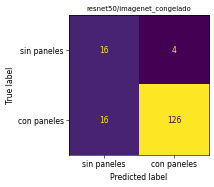

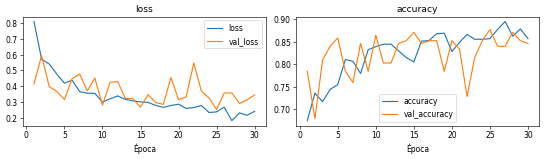


resnet50/imagenet_finetuning · fecha original: 2026-11-03T16:52:43 · commit: 7c8ebe1dab70822306565db12cf4a620b24a4f4c
SHA-256 de las fuentes consultadas:
config.json 4c59652d06ff64b711a1524cacde5351f867b64b3b23e0191182ecf154c64282
metricas.json 9476f479a8607ac852102269891a4e56e9d4bc4a2293598db568125c9012c88d
predicciones_val.csv 5fdc39e902693e3192e31ca9112b39bf80386179b5628a6ae934a9d623500845


,modelo,modo,fecha,commit,sin_pesos,params.modelo,params.receta,params.img_size,params.batch_size,params.semilla,...,params.entorno.paquetes.scikit-learn,params.entorno.gpu,params.estrategia,params.inicializacion,params.checkpoint_inicial,params.lr,params.epocas_max,params.epocas_adicionales_max,params.paciencia,params.reducir_lr
0,resnet50,imagenet_finetuning,2026-11-03T16:52:43,7c8ebe1dab70822306565db12cf4a620b24a4f4c,False,ResNet50,comun_v2,256,32,42,...,1.6.1,"[PhysicalDevice(name='/physical_device:GPU:0',...",todo_el_extractor_sin_batchnorm,mejor_imagenet_congelado,/content/drive/MyDrive/PDI-TP/resultados/resne...,0.00001,20,20,10,None


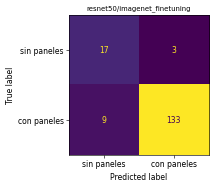

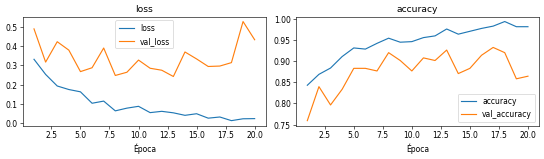


resnet50/aleatorio · fecha original: 2026-11-03T17:15:17 · commit: 7c8ebe1dab70822306565db12cf4a620b24a4f4c
SHA-256 de las fuentes consultadas:
config.json 9db66a4bf781fec57915d98d5f8bbc5d8be8efe40c22326ead7ac0e61db92ad1
metricas.json 53dd772636016f7e60cd8f61c1bc065ed5c2b82c6f21d244cd36db8602434c09
predicciones_val.csv b02b6001aed1e34850a79bd7b4e1e66d7f4f8a9d13c4b351568b20d9d230f9c0


,modelo,modo,fecha,commit,sin_pesos,params.modelo,params.receta,params.img_size,params.batch_size,params.semilla,...,params.estrategia,params.inicializacion,params.lr,params.epocas_max,params.paciencia,params.momentum_batchnorm,params.inicio_parada,params.reducir_lr.monitor,params.reducir_lr.factor,params.reducir_lr.paciencia
0,resnet50,aleatorio,2026-11-03T17:15:17,7c8ebe1dab70822306565db12cf4a620b24a4f4c,False,ResNet50,comun_v2,256,32,42,...,toda_la_red,aleatoria,0.001,60,10,0.9,20,val_loss,0.5,3


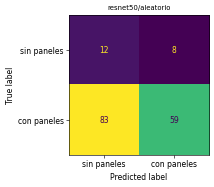

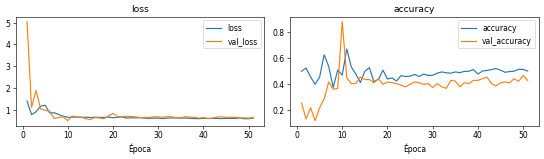

In [1]:
# Consulta independiente: ejecutar solo esta celda para mostrar resultados guardados.
# Las celdas de entrenamiento de arriba no se ejecutan en la copia publicada.
import sys
from pathlib import Path
raiz_consulta = next((p for p in (Path.cwd(), *Path.cwd().parents)
                     if (p / "pdi_tp" / "lectura_entrega.py").is_file()), None)
if raiz_consulta is None:
    raise FileNotFoundError("Abrí el notebook desde el repositorio clonado.")
sys.path.insert(0, str(raiz_consulta))
from pdi_tp import lectura_entrega
lectura_entrega.mostrar_modelo("resnet50")
